# 02. Key driver framework applied to each stakeholder group

**Business question.** For each stakeholder group, which attributes drive the outcome, how well does the brand
perform on them, and where should effort go first?

The framework in `src/kda.py` does the whole run in one call per group:

1. **Importance** = Pearson correlation of each attribute with the outcome (pairwise complete).
2. **Performance** = mean rating of the attribute.
3. **Quadrant**, using an importance threshold of **r = 0.2** and the group's average attribute rating as the
   performance threshold:
   * Strengths: important and rated above average
   * Priority fixes: important and rated below average
   * Maintain: rated above average but weakly linked to the outcome
   * Low priority: weak link and below-average rating
4. A labelled quadrant chart and structured hypothesis statements.

Every group run is timed end to end.

In [1]:
import os
# Single-threaded BLAS: avoids thread oversubscription and keeps timings reproducible on shared machines.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from plotting import apply_style, PALETTE
from generate_data import ATTRIBUTES, OUTCOME, OUTCOME_LABELS
apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)

RAW = Path("../data/raw/stakeholder_survey.csv")
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
FIGS = Path("../reports/figures"); FIGS.mkdir(parents=True, exist_ok=True)
DRIVERS = list(ATTRIBUTES)
GROUPS = ["Physicians", "Pharmacists", "Patients", "Payers"]

import time
from kda import run_kda, driver_table, plot_quadrant, QUADRANT_ORDER, IMPORTANCE_THRESHOLD

In [2]:
df = pd.read_csv(RAW)
print(f"importance threshold r = {IMPORTANCE_THRESHOLD}")
df["stakeholder_group"].value_counts().reindex(GROUPS)

importance threshold r = 0.2


stakeholder_group
Physicians      600
Pharmacists     400
Patients       1200
Payers          150
Name: count, dtype: int64

## Automated run across all groups (timed)

`run_kda` loops over the groups and, for each, builds the driver table, renders and saves the quadrant chart, and
writes the hypotheses. The timings below are wall-clock seconds measured inside the function.

In [3]:
t0 = time.perf_counter()
results = run_kda(df, "stakeholder_group", DRIVERS, OUTCOME, OUTCOME_LABELS, ATTRIBUTES, fig_dir=FIGS)
total_s = time.perf_counter() - t0

timing = pd.DataFrame({g: {"respondents": r.n_respondents, "drivers": len(r.table), **r.timings,
                           "total_s": r.seconds, "hypotheses": len(r.hypotheses)}
                       for g, r in results.items()}).T
timing = timing.astype({"respondents": int, "drivers": int, "hypotheses": int}).loc[GROUPS]
print(f"all {len(results)} groups: {total_s:.2f}s end to end")
timing

all 4 groups: 1.20s end to end


,respondents,drivers,metrics_s,chart_s,hypotheses_s,total_s,hypotheses
Physicians,600,24,0.040,0.266,0.008,0.314,10
Pharmacists,400,24,0.037,0.205,0.007,0.249,9
Patients,1200,24,0.029,0.322,0.012,0.363,9
Payers,150,24,0.041,0.227,0.008,0.276,9


In [4]:
timing.to_csv(PROCESSED / "kda_run_timing.csv")
repeat = []
for _ in range(5):
    t0 = time.perf_counter()
    run_kda(df, "stakeholder_group", DRIVERS, OUTCOME, OUTCOME_LABELS, ATTRIBUTES)
    repeat.append(time.perf_counter() - t0)
print(f"5 repeat runs (all groups, charts in memory): median {np.median(repeat):.2f}s, "
      f"range {min(repeat):.2f}-{max(repeat):.2f}s")

5 repeat runs (all groups, charts in memory): median 0.24s, range 0.23-0.27s


## Quadrant charts per group

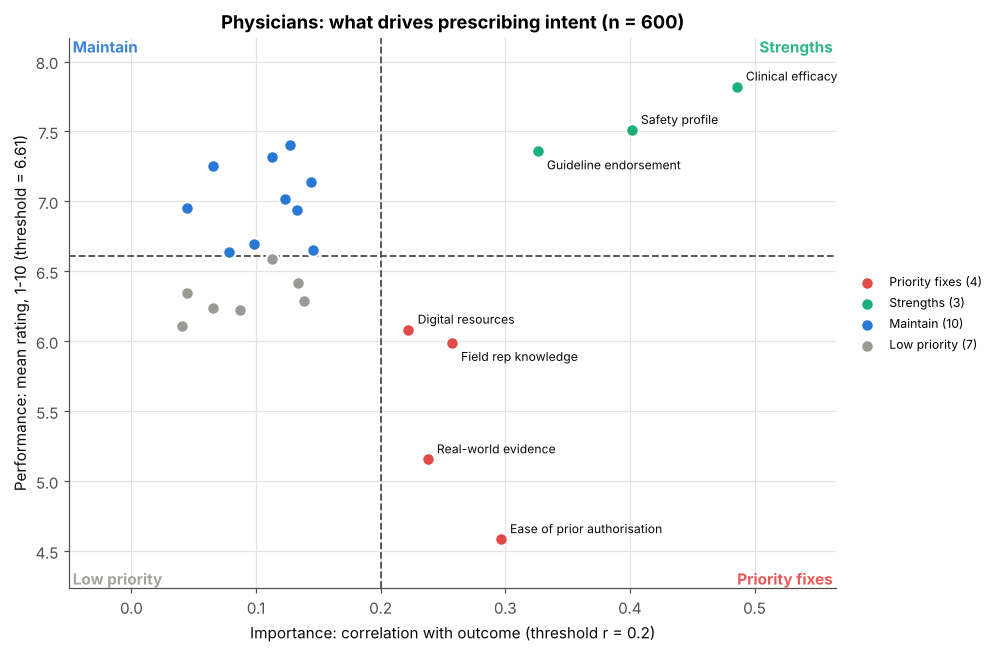

,importance,p_value,performance,performance_gap,quadrant
Clinical efficacy,0.486,0.000,7.821,1.207,Strengths
Safety profile,0.402,0.000,7.510,0.897,Strengths
Guideline endorsement,0.326,0.000,7.361,0.747,Strengths
Ease of prior authorisation,0.296,0.000,4.585,-2.028,Priority fixes
Field rep knowledge,0.257,0.000,5.991,-0.622,Priority fixes
Real-world evidence,0.238,0.000,5.156,-1.457,Priority fixes
Digital resources,0.222,0.000,6.083,-0.530,Priority fixes


In [5]:
def show_group(g):
    r = results[g]
    plot_quadrant(r.table, f"{g}: what drives {OUTCOME_LABELS[g]} (n = {r.n_respondents:,})", labels=ATTRIBUTES)
    plt.show()
    cols = ["importance", "p_value", "performance", "performance_gap", "quadrant"]
    t = r.table[cols].copy()
    t.index = [ATTRIBUTES[d] for d in t.index]
    return t[t["importance"] >= IMPORTANCE_THRESHOLD]

show_group("Physicians")

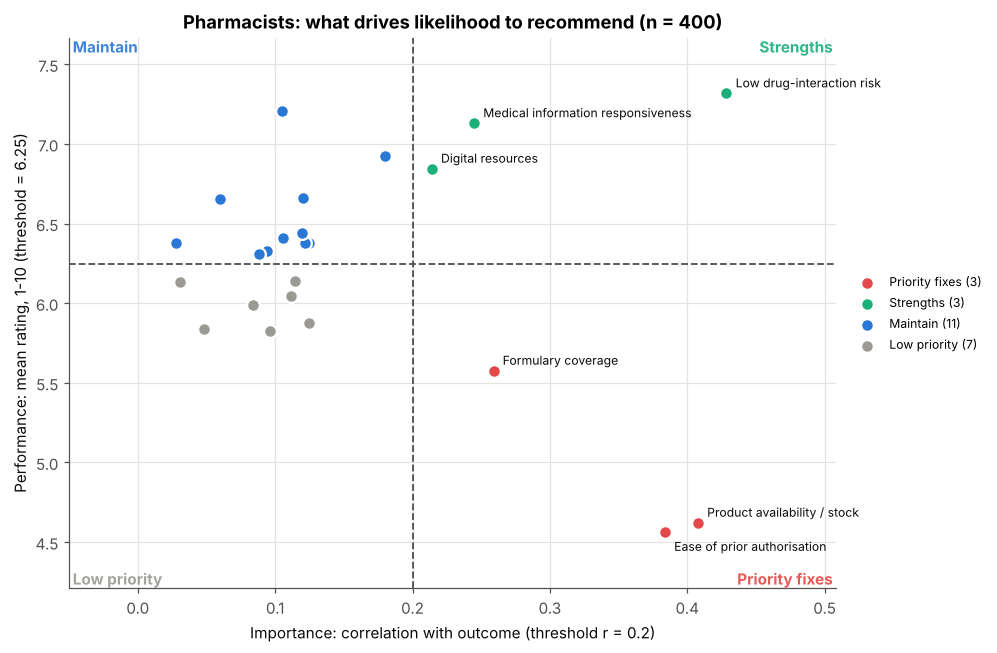

,importance,p_value,performance,performance_gap,quadrant
Low drug-interaction risk,0.429,0.000,7.318,1.069,Strengths
Product availability / stock,0.408,0.000,4.621,-1.628,Priority fixes
Ease of prior authorisation,0.384,0.000,4.560,-1.688,Priority fixes
Formulary coverage,0.259,0.000,5.576,-0.673,Priority fixes
Medical information responsiveness,0.245,0.000,7.130,0.881,Strengths
Digital resources,0.214,0.000,6.845,0.596,Strengths


In [6]:
show_group("Pharmacists")

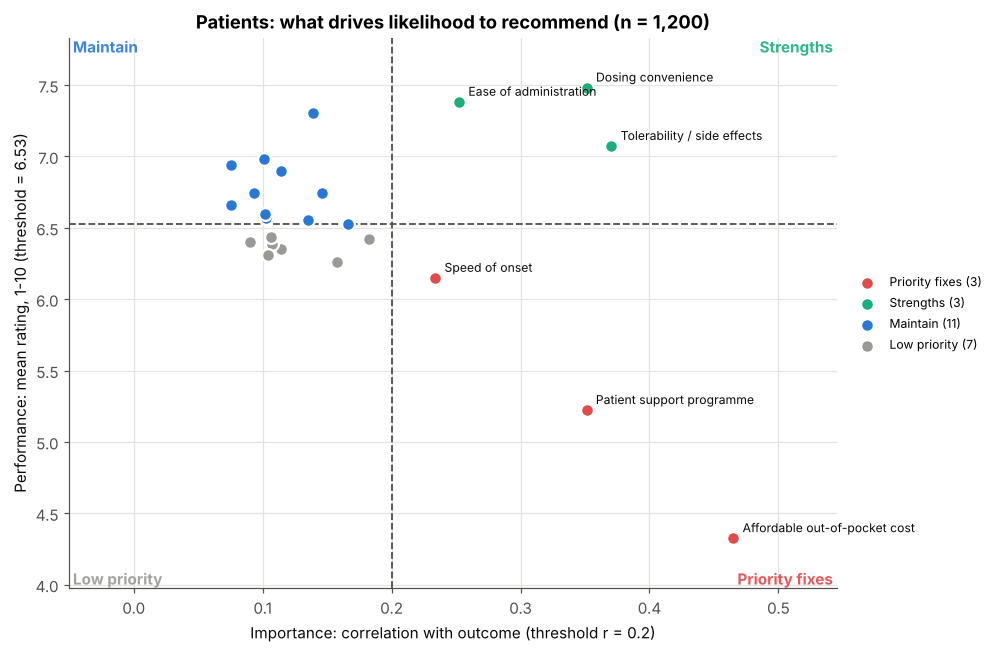

,importance,p_value,performance,performance_gap,quadrant
Affordable out-of-pocket cost,0.465,0.000,4.325,-2.204,Priority fixes
Tolerability / side effects,0.371,0.000,7.073,0.544,Strengths
Dosing convenience,0.351,0.000,7.482,0.953,Strengths
Patient support programme,0.351,0.000,5.223,-1.307,Priority fixes
Ease of administration,0.252,0.000,7.383,0.853,Strengths
Speed of onset,0.234,0.000,6.149,-0.380,Priority fixes


In [7]:
show_group("Patients")

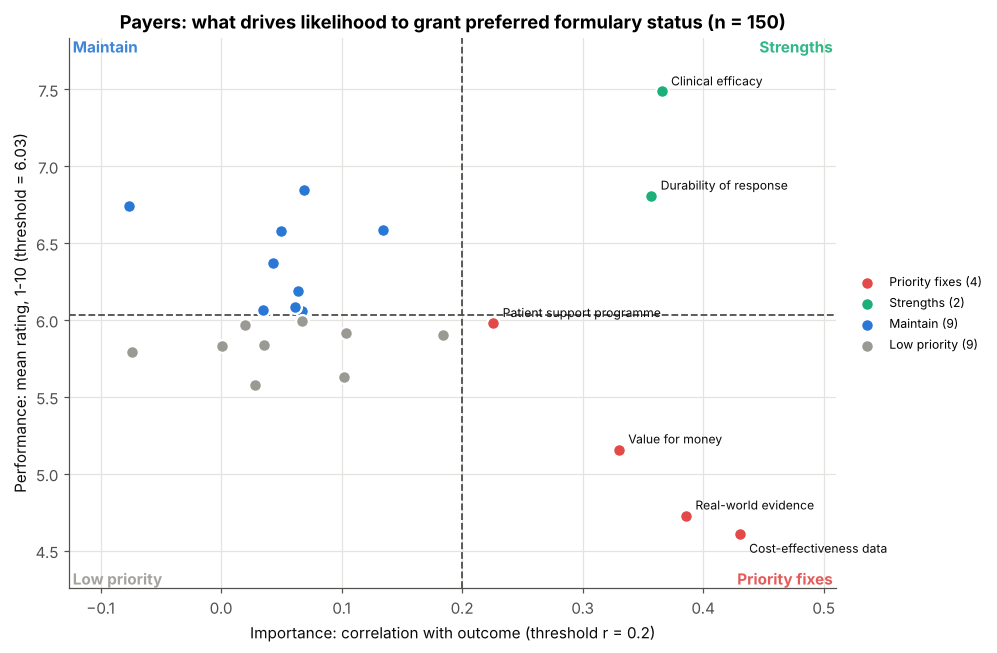

,importance,p_value,performance,performance_gap,quadrant
Cost-effectiveness data,0.431,0.000,4.605,-1.425,Priority fixes
Real-world evidence,0.386,0.000,4.728,-1.303,Priority fixes
Clinical efficacy,0.366,0.000,7.486,1.456,Strengths
Durability of response,0.357,0.000,6.808,0.778,Strengths
Value for money,0.330,0.000,5.158,-0.873,Priority fixes
Patient support programme,0.226,0.006,5.979,-0.051,Priority fixes


In [8]:
show_group("Payers")

## All four groups side by side

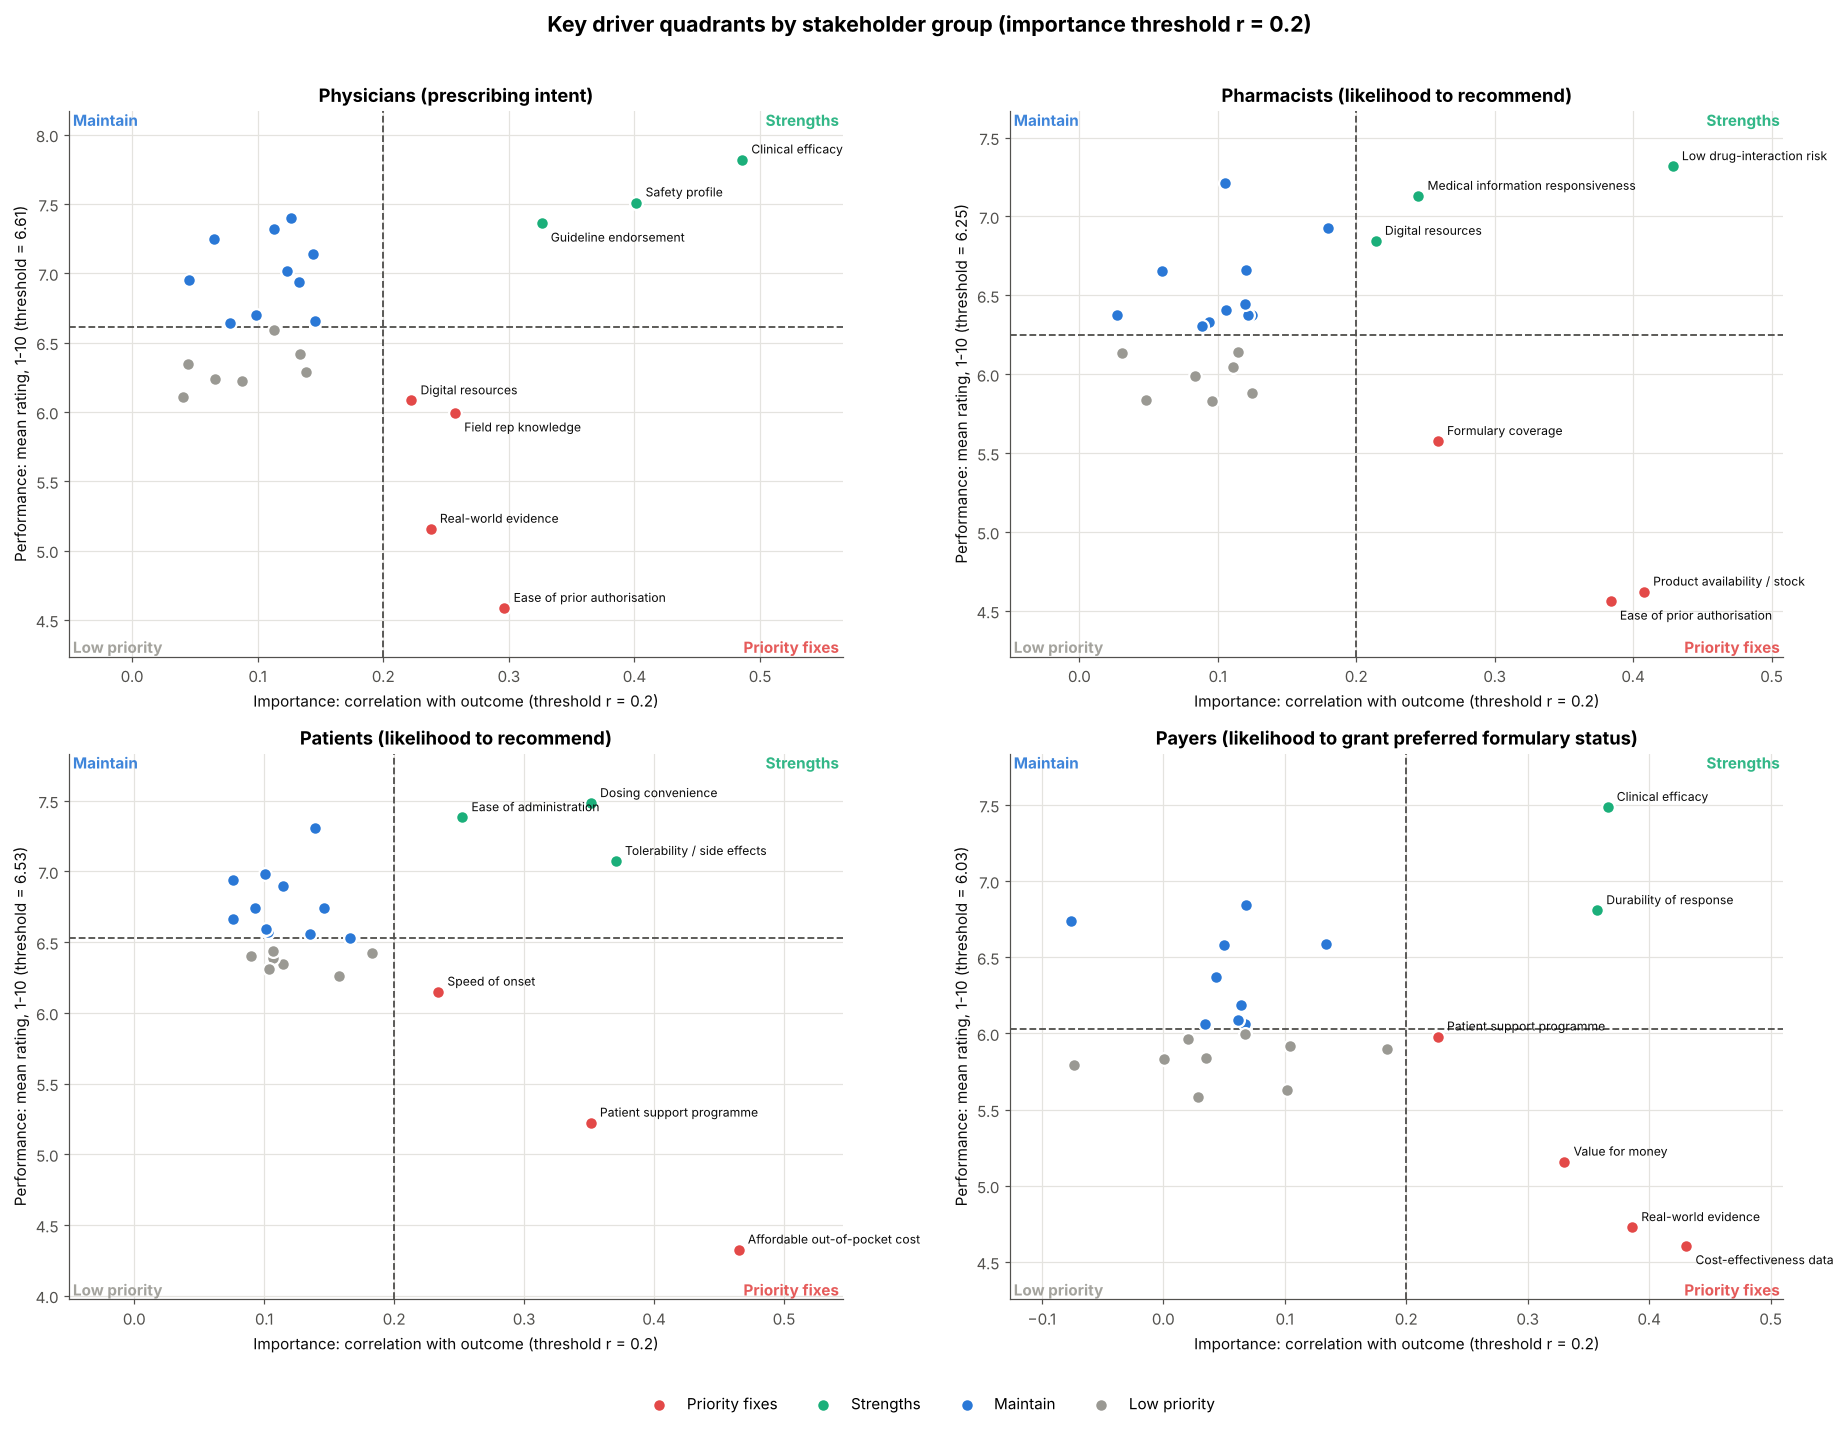

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
for ax, g in zip(axes.ravel(), GROUPS):
    plot_quadrant(results[g].table, f"{g} ({OUTCOME_LABELS[g]})", labels=ATTRIBUTES, ax=ax)
    ax.get_legend().remove()
handles, lbls = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, [l.split(" (")[0] for l in lbls], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Key driver quadrants by stakeholder group (importance threshold r = 0.2)", fontweight="bold", fontsize=14)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(FIGS / "02_quadrants_all_groups.png")
plt.show()

## Quadrant membership across groups

In [10]:
quad = pd.DataFrame({g: results[g].table["quadrant"] for g in GROUPS})
counts = quad.apply(lambda s: s.value_counts()).reindex(QUADRANT_ORDER).fillna(0).astype(int)
counts

,Physicians,Pharmacists,Patients,Payers
Priority fixes,4,3,3,4
Strengths,3,3,3,2
Maintain,10,11,11,9
Low priority,7,7,7,9


In [11]:
code = {"Priority fixes": "FIX", "Strengths": "STR", "Maintain": "MNT", "Low priority": "-"}
matrix = quad.replace(code)
matrix.index = [ATTRIBUTES[d] for d in matrix.index]
important_anywhere = (pd.DataFrame({g: results[g].table["importance"] for g in GROUPS}) >= IMPORTANCE_THRESHOLD).any(axis=1)
matrix[important_anywhere.reindex(quad.index).values].sort_index()

,Physicians,Pharmacists,Patients,Payers
Affordable out-of-pocket cost,MNT,MNT,FIX,-
Clinical efficacy,STR,MNT,-,STR
Cost-effectiveness data,MNT,MNT,MNT,FIX
Digital resources,FIX,STR,MNT,-
Dosing convenience,MNT,-,STR,-
Durability of response,-,-,MNT,STR
Ease of administration,-,MNT,STR,-
Ease of prior authorisation,FIX,FIX,MNT,-
Field rep knowledge,FIX,MNT,MNT,MNT
Formulary coverage,-,FIX,-,-


In [12]:
long = pd.concat([r.table.assign(group=g) for g, r in results.items()]).reset_index()
long.to_csv(PROCESSED / "driver_tables.csv", index=False)
print(f"saved {len(long)} driver-group rows")

saved 96 driver-group rows


## Findings

* One call to `run_kda` produced, for all four groups, the driver table, a saved quadrant chart and the hypothesis
  set in **1.20 seconds** (0.25 to 0.36 s per group, most of it chart rendering and saving). Without writing PNGs,
  the full four-group run has a median of 0.24 s over five repeats.
* Drivers clearing r = 0.2: Physicians 7, Pharmacists 6, Patients 6, Payers 6 (of 24).
* Strongest driver per group: clinical efficacy for physicians (r = 0.486), low drug-interaction risk for
  pharmacists (0.429), affordable out-of-pocket cost for patients (0.465), cost-effectiveness data for payers (0.431).
* Priority fixes (important, rated below average):
  * Physicians: ease of prior authorisation (r = 0.296, rated 4.59), field rep knowledge, real-world evidence,
    digital resources.
  * Pharmacists: product availability (0.408, 4.62), ease of prior authorisation (0.384, 4.56), formulary coverage.
  * Patients: affordable out-of-pocket cost (0.465, 4.33), patient support programme (0.351, 5.22), speed of onset.
  * Payers: cost-effectiveness data (0.431, 4.61), real-world evidence (0.386, 4.73), value for money, patient support
    programme.
* Most attributes (9 to 11 per group) fall in "Maintain": rated above average but weakly tied to the outcome, which
  makes them candidates for budget reallocation.